# 5. AI Feature: "Ask the Portfolio" chat

The brief: *pick one AI feature, embedded in the dashboard, not standalone.* This build's AI feature is
**"Ask the Portfolio"**: natural-language Q&A over the dashboard data (e.g. *"which segment has the highest default
rate this quarter?"*) using an LLM, grounded in the actual underlying data, with no hallucinated numbers. Dashboard page:
**AI feature → Ask the Portfolio** (`src/chat.py`).

| Brief: "state clearly" | Section |
|---|---|
| What triggers the AI feature | 5.2 |
| What a false positive / negative looks like | 5.4 |
| The human-in-the-loop step | 5.5 |

A second AI feature, anomaly detection, is shown as a **bonus** at the end (section B).

## 5.1 How it stays grounded

- The LLM (NVIDIA Nemotron-3 Ultra; fallback Nemotron-3.5 Lightning) never sees raw data and never does its own
  arithmetic. It can only call 8 query tools (overview, segment breakdown, highest-default segments, cross-tab, vintage
  trend, account lookup, top accounts, model info), each computing numbers with `src/portfolio.py`.
- After the model answers, **every number in the reply is matched against the tool results** (allowing for rounding
  and units), and a number that belongs to a segment must sit in a sentence about that segment. Numbers that fail
  either test are shown to the user as a warning; numbers only repeated from the question are labelled as such.
- If there is no API key or the service fails, a rule-based router answers the common questions offline, through
  the same tools and the same check (section 5.3).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import json
import pandas as pd
import matplotlib.pyplot as plt
from nbstyle import BLUE, ORANGE, STATUS, rate_barh, paired_barh, heatmap
import portfolio as pf
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
book = pf.load_book()

from pathlib import Path
REPORTS = Path("../reports")
evaluation = json.loads((REPORTS / "anomaly_eval.json").read_text())
import chat

## 5.2 What triggers it

A user's question in the dashboard's chat box (typed, or picked from the suggested questions), optionally limited to
the dashboard's current filters. The examples below run live against NVIDIA's API, starting with the brief's own
example question.

In [2]:
questions = [
    "Which segment has the highest default rate this quarter?",
    "Which loan type has the highest default rate, and how much of our exposure is in it?",
    "Compare default rates across income bands for unemployed customers.",
    "What will our default rate be next year?",
]
for q in questions:
    result = chat.ask(book, q)
    v = result["verification"]
    print("Q:", q)
    print("Tools:", [(c["tool"], c["arguments"]) for c in result["tool_calls"]])
    print("A:", result["answer"])
    print(f"Check: {v['status']} ({len(v['verified'])} found in the data; not found: {v['unverified']}; "
          f"wrong segment: {v['misattributed']})  [{result['mode']}]")
    print("-" * 100)

Q: Which segment has the highest default rate this quarter?
Tools: [('highest_default_segments', {'order': 'highest', 'filters': {'origination_quarter': ['2023Q4']}, 'top_n': 5})]
A: The **30‑50k income band** has the highest default rate in the latest origination quarter (2023Q4) at **29.5%** (61 accounts).  

Because this segment contains fewer than 100 accounts, the rate is based on a small sample and is less reliable.  

The next highest segments in 2023Q4 are:  
- **IT/Tech occupation sector** – 26.3% (57 accounts, small sample)  
- **21‑25 age band** – 25.3% (75 accounts, small sample)  
- **Loan‑to‑income 2x+** – 22.0% (59 accounts, small sample)  
- **Other occupation sector** – 21.2% (52 accounts, small sample)  

All of these top segments are flagged as small samples.
Check: verified (18 found in the data; not found: []; wrong segment: [])  [llm]
----------------------------------------------------------------------------------------------------


Q: Which loan type has the highest default rate, and how much of our exposure is in it?
Tools: [('segment_breakdown', {'dimension': 'loan_type', 'sort_by': 'default_rate_pct'})]
A: **Mortgage** has the highest default rate at **24.7%** (1,432 accounts). It also holds the largest share of portfolio exposure: **$314.5 million**, which is **52.3%** of total exposure. Its default rate is **53.1% higher** than the portfolio average (lift of 1.53).
Check: verified (6 found in the data; not found: []; wrong segment: [])  [llm]
----------------------------------------------------------------------------------------------------


Q: Compare default rates across income bands for unemployed customers.
Tools: [('segment_breakdown', {'filters': {'employment_type': ['Unemployed']}, 'dimension': 'income_band'})]
A: Among unemployed customers (718 accounts, 35.0% overall default rate), default rates fall sharply as income rises:

- **<30k**: 44.3% default rate (228 accounts)  
- **30–50k**: 36.1% default rate (230 accounts)  
- **50–75k**: 27.0% default rate (204 accounts)  
- **75–100k**: 21.6% default rate (51 accounts) — small sample, fewer than 100 accounts  
- **100k+**: 20.0% default rate (5 accounts) — small sample, fewer than 100 accounts  

The two highest income bands rest on fewer than 100 accounts each, so their rates are less reliable.
Check: verified (23 found in the data; not found: []; wrong segment: [])  [llm]
----------------------------------------------------------------------------------------------------


Q: What will our default rate be next year?
Tools: [('get_overview', {})]
A: I can't forecast next year's default rate for new originations—the tools only cover the existing portfolio (originations 2018Q1–2023Q4).  

For the current book of 14,685 accounts, the model’s average predicted probability of default is **16.1%**, which matches the observed default rate of **16.1%** (2,364 defaulted accounts). That figure describes the risk of loans already on the books, not a projection for future lending.

If you’d like, I can show how default rates have trended by origination quarter or year to give a sense of historical patterns.
Check: verified (6 found in the data; not found: []; wrong segment: [])  [llm]
----------------------------------------------------------------------------------------------------


## 5.3 The number check catches invented and misplaced figures

The same checker run on deliberately wrong answers, using real tool output: one invents figures, one quotes a real figure for the wrong segment.

In [3]:
call = {"tool": "segment_breakdown", "arguments": {"dimension": "loan_type"},
        "result": chat.run_tool(book, "segment_breakdown", {"dimension": "loan_type"})}
answers = {
    "honest": "Mortgages default most, at 24.7% across 1,432 accounts, holding 52.3% of exposure.",
    "invented": "Mortgages default most, at 31.2% across 1,432 accounts, and losses will rise 8% next year.",
    "misplaced": "Auto loans default most, at 24.7% across 1,432 accounts.",
}
for name, text in answers.items():
    v = chat.verify(text, [call])
    print(f"{name}: {text}")
    print(f"   -> {v['status']}: found in the data {v['verified']}; not in the data {v['unverified']}; "
          f"wrong segment {[(m['number'], 'belongs to ' + ', '.join(m['belongs_to'])) for m in v['misattributed']]}")


honest: Mortgages default most, at 24.7% across 1,432 accounts, holding 52.3% of exposure.
   -> verified: found in the data ['24.7%', '1,432', '52.3%']; not in the data []; wrong segment []
invented: Mortgages default most, at 31.2% across 1,432 accounts, and losses will rise 8% next year.
   -> check: found in the data ['1,432']; not in the data ['31.2%']; wrong segment [('8%', 'belongs to personal loan')]
misplaced: Auto loans default most, at 24.7% across 1,432 accounts.
   -> check: found in the data []; not in the data []; wrong segment [('24.7%', 'belongs to mortgage'), ('1,432', 'belongs to mortgage')]


### Offline fallback

Without an API key, or if the service is down, a rule-based router reads the question (filters such as "unemployed", one or two dimensions, rankings, trends, accounts), calls the same tools and runs the same check. Every suggested question, answered offline:

In [4]:
for q in chat.SUGGESTED_QUESTIONS:
    r = chat.offline_answer(book, q, reason="offline demo")
    print("Q:", q)
    print("A:", r["answer"])
    print(f"Check: {r['verification']['status']} ({r['verification']['numbers_checked']} numbers)")
    print("-" * 100)

Q: Which segment has the highest default rate this quarter?
A: For loans originated in 2023Q4, the segment with the highest default rate is income band 30-50k at 29.5% (61 accounts), 1.93x the average of 15.3%. It rests on few accounts, so treat it as indicative. Next: occupation sector IT/Tech 26.3% (57 accounts); age band 21-25 25.3% (75 accounts).
Check: verified (13 numbers)
----------------------------------------------------------------------------------------------------


Q: Which loan type has the highest default rate, and how much of our exposure is in it?
A: By loan type, Mortgage has the highest default rate at 24.7% (1,432 accounts), 1.53x the average of 16.1%, and holds 52.3% of exposure ($314.5M). The lowest is Auto Loan at 13.9%.
Check: verified (7 numbers)
----------------------------------------------------------------------------------------------------
Q: Compare default rates across income bands for unemployed customers.
A: Default rate by income band for employment type Unemployed (718 accounts, 35.0% overall): <30k 44.3% (228 accounts), 30-50k 36.1% (230 accounts), 50-75k 27.0% (204 accounts), 75-100k 21.6% (51 accounts, small sample), 100k+ 20.0% (5 accounts, small sample).
Check: verified (20 numbers)
----------------------------------------------------------------------------------------------------
Q: Which region and loan type combination is riskiest?
A: The highest-risk region x loan type combination is South Mortgage at 27.3% (381 

Q: Why is account ACC203222 rated high risk?
A: ACC203222 (Mortgage, North) has a predicted PD of 82.8%, Very High risk, higher than 99.9% of accounts. Main factors raising its risk: Annual income $12,000; Loan / annual income 23.03x; Late payments (12 months) 5; Bureau: average days past due 46; Missed payments (12 months) 2. It is also flagged as an anomaly (High severity).
Check: verified (7 numbers)
----------------------------------------------------------------------------------------------------


## 5.4 What a false positive / negative looks like

- **False positive:** a confident answer the data can't really support, e.g. reading "this quarter" in a way the user
  didn't mean, applying the wrong filter, or quoting a segment rate built on very few accounts. Mitigations: the period
  used is always stated, small segments are flagged, the queries behind every answer are shown, and numbers that are
  not in the data, or sit next to the wrong segment, are flagged.
- **False negative:** "I can't answer that" when the data could, usually because of phrasing, or an answer at a coarser
  cut than asked. Mitigations: suggested questions, and the same cut one click away in the Portfolio view and Segment
  drill-down.

## 5.5 The human-in-the-loop step

Answers are for exploration, not decisions. Before a figure goes into a decision or a report, the analyst checks it in
the "data behind this answer" panel and rates the answer (thumbs up or down, logged to `data/review/chat_feedback.csv`
for monthly review). In production the LLM would run as an NVIDIA NIM inside the bank's own environment so that no
customer data leaves it.

---

# B. Bonus AI feature: anomaly detection

Beyond the brief's one feature. Dashboard page: **Bonus AI → Anomaly review** (`src/anomaly.py`).

| Trigger | Rule | Severity |
|---|---|---|
| Peer outlier | Isolation Forest on each account's *percentile within its peer group* (same loan type and income band) for 10 risk metrics, counting only the risky direction; the 5% most unusual are flagged | High for the top 1%, else Medium |
| Affordability breach | Monthly instalment larger than monthly income | High |
| Payment shock | 2+ missed payments in the last 3 months after 9 months with no missed payment (vs its own history) | Medium |

The target is never used to build flags; it is used below only to check whether flags concentrate real risk.

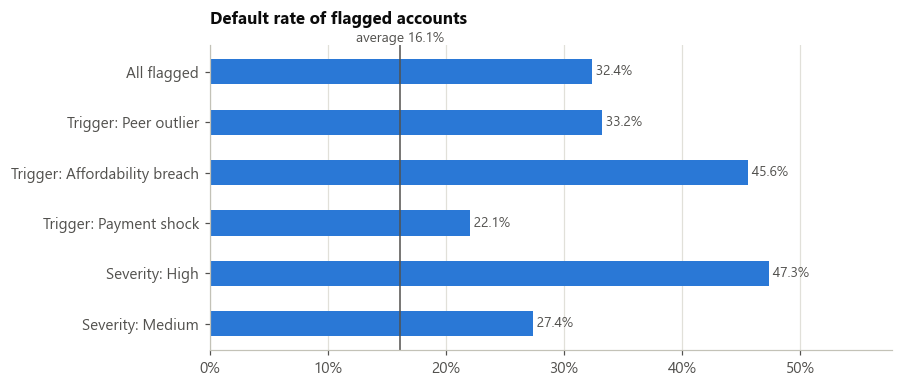

Precision 32.4% | recall 11.2% | 80% of flags are also High/Very High for the PD model


,group,accounts,default_rate,lift
0,All flagged,815,32.4%,2.01x
1,Trigger: Peer outlier,735,33.2%,2.06x
2,Trigger: Affordability breach,79,45.6%,2.83x
3,Trigger: Payment shock,68,22.1%,1.37x
4,Severity: High,205,47.3%,2.94x
5,Severity: Medium,610,27.4%,1.70x


In [5]:
summary = pd.DataFrame([
    {"group": "All flagged", "accounts": evaluation["flagged"], "default_rate": evaluation["flagged_default_rate"]},
    *[{"group": f"Trigger: {k}", "accounts": v["accounts"], "default_rate": v["default_rate"]}
      for k, v in evaluation["by_trigger"].items()],
    *[{"group": f"Severity: {k}", "accounts": v["accounts"], "default_rate": v["default_rate"]}
      for k, v in evaluation["by_severity"].items()],
])
summary["lift"] = summary.default_rate / evaluation["portfolio_default_rate"]
fig, ax = plt.subplots(figsize=(8, 3.6))
rate_barh(ax, summary.group, summary.default_rate, average=evaluation["portfolio_default_rate"],
          title="Default rate of flagged accounts")
plt.show()
print(f"Precision {evaluation['precision']:.1%} | recall {evaluation['recall']:.1%} | "
      f"{evaluation['share_flagged_also_model_high_risk']:.0%} of flags are also High/Very High for the PD model")
summary.style.format({"default_rate": "{:.1%}", "lift": "{:.2f}x"})

In [6]:
cols = ["account_id", "loan_type", "income_band", "anomaly_severity", "anomaly_reasons", "pd", "risk_band"]
print("FALSE POSITIVES: flagged, but the loan kept performing")
display(book[book.anomaly_flag.eq(1) & book.target_default.eq(0)].sort_values("anomaly_score", ascending=False)[cols].head(4))
print("FALSE NEGATIVES: defaulted, but looked normal to both the detector and the model")
book[book.anomaly_flag.eq(0) & book.target_default.eq(1) & book.risk_band.eq("Low")][
    ["account_id", "loan_type", "income_band", "rep_n_missed", "rep_n_late", "emi_to_income", "pd", "risk_band"]].head(4)

FALSE POSITIVES: flagged, but the loan kept performing


,account_id,loan_type,income_band,anomaly_severity,anomaly_reasons,pd,risk_band
11483,ACC211484,Personal Loan,<30k,High,Instalment is 221% of monthly income (affordability breach); Bureau: debt / income 4.42x vs peer median 0.54x (highe...,0.427344,Very High
1893,ACC201894,Business Loan,<30k,High,Instalment is 577% of monthly income (affordability breach); Bureau: debt / income 7.88x vs peer median 0.69x (highe...,0.408229,Very High
944,ACC200945,Business Loan,<30k,High,Instalment is 442% of monthly income (affordability breach); Bureau: debt / income 3.09x vs peer median 0.69x (highe...,0.562431,Very High
11452,ACC211453,Mortgage,30-50k,High,Bureau: average days past due 35.8 vs peer median 14.5 (higher than 94% of peers); Longest run of missed payments 2 ...,0.584727,Very High


FALSE NEGATIVES: defaulted, but looked normal to both the detector and the model


,account_id,loan_type,income_band,rep_n_missed,rep_n_late,emi_to_income,pd,risk_band
68,ACC200069,Auto Loan,50-75k,0,2,0.041228,0.070194,Low
117,ACC200118,Personal Loan,75-100k,0,0,0.118848,0.071629,Low
136,ACC200137,Personal Loan,100k+,0,0,0.104149,0.069744,Low
197,ACC200198,Personal Loan,100k+,0,1,0.022050,0.062702,Low


Flagged accounts default at about twice the portfolio rate, and High-severity flags at nearly three times. A false
positive is a flag on an account that keeps paying (about two thirds of flags), so a flag is a prompt to look, not a
verdict; a false negative is a default that looked normal (the detector catches about 1 in 9 defaults; the PD model
covers the whole book). **Human in the loop:** analysts confirm (escalate to an early-intervention call) or dismiss
with a reason, every decision is logged in `data/review/anomaly_reviews.csv`, and no customer is contacted or
re-priced automatically.